# Fixed-point iteration and convergence

Two rearrangements are evaluated with a tolerance and a finite iteration limit.

$$2x^3-x^2+x-1=0,\qquad x_{k+1}=\sqrt[3]{\frac{x_k^2-x_k+1}{2}}.$$

Root: 0.7389836210; residual: -1.44e-09
Coupled system: x=0.99999999, y=1.00000000


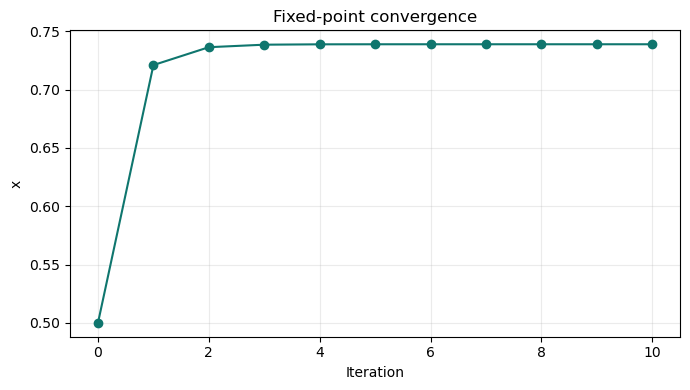

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def fixed_point(g, start, tolerance=1e-8, limit=100):
    values = [float(start)]
    for _ in range(limit):
        value = float(g(values[-1]))
        if not np.isfinite(value):
            raise ValueError('Non-finite iterate')
        values.append(value)
        if abs(values[-1] - values[-2]) < tolerance:
            return np.array(values)
    raise RuntimeError('Iteration did not converge')

g = lambda x: np.cbrt((x*x - x + 1) / 2)
values = fixed_point(g, 0.5)
root = values[-1]
residual = 2*root**3 - root**2 + root - 1
print(f"Root: {root:.10f}; residual: {residual:.2e}")
assert abs(residual) < 1e-7

x, y = .5, .5
for iteration in range(100):
    next_x = (3*y*x*x + 7) / 10
    next_y = (y*y + 4) / 5
    change = max(abs(next_x-x), abs(next_y-y))
    x, y = next_x, next_y
    if change < 1e-8:
        break
print(f"Coupled system: x={x:.8f}, y={y:.8f}")
assert abs(3*y*x*x-10*x+7) < 1e-6 and abs(y*y-5*y+4) < 1e-6

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(len(values)), values, 'o-', color='#0f766e')
ax.set(xlabel='Iteration', ylabel='x', title='Fixed-point convergence')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()